In [1]:
# Importation des bibliothèques nécessaires
import numpy as np
import matplotlib.pyplot as plt

# ÉTAPE 1.1 : Fixer la seed pour reproductibilité
np.random.seed(101)
print("✓ Seed fixée à 101 pour reproductibilité")

# ÉTAPE 1.2 : Générer les notes aléatoires
# 100 étudiants × 5 modules, notes entre 0 et 20
grades_of_students = np.random.randint(0, 21, size=(100, 5))
print("✓ Notes générées : tableau 100×5")
print(f"  Shape : {grades_of_students.shape}")
print(f"  Type : {grades_of_students.dtype}")

# ÉTAPE 1.3 : Définir les noms des modules
modules = ['THL', 'DSS', 'DB', 'SE', 'RE']
print(f"✓ Modules définis : {modules}")

# ÉTAPE 1.4 : Afficher un aperçu
print("\n=== APERÇU DES 5 PREMIERS ÉTUDIANTS ===")
print("(Chaque ligne = un étudiant, colonnes = modules)")
print(grades_of_students[:5])

✓ Seed fixée à 101 pour reproductibilité
✓ Notes générées : tableau 100×5
  Shape : (100, 5)
  Type : int64
✓ Modules définis : ['THL', 'DSS', 'DB', 'SE', 'RE']

=== APERÇU DES 5 PREMIERS ÉTUDIANTS ===
(Chaque ligne = un étudiant, colonnes = modules)
[[11 17  6 11 15]
 [ 9 13  8  4  8]
 [ 0 14  5 12  8]
 [17 19 15  8 19]
 [19  2 12  8 19]]


In [2]:
print("\n" + "="*50)
print("ÉTAPE 2 : STATISTIQUES DE BASE")
print("="*50)

# ÉTAPE 2.1 : Moyenne par étudiant
print("\n1. MOYENNE PAR ÉTUDIANT :")
mean_per_student = np.mean(grades_of_students, axis=1)
print(f"   Calcul : np.mean(grades_of_students, axis=1)")
print(f"   axis=1 → moyenne HORIZONTALE (par ligne)")
print(f"   Résultat shape : {mean_per_student.shape} → 100 moyennes")
print(f"   5 premières moyennes : {mean_per_student[:5]}")

# ÉTAPE 2.2 : Moyenne par module
print("\n2. MOYENNE PAR MODULE :")
mean_per_module = np.mean(grades_of_students, axis=0)
print(f"   Calcul : np.mean(grades_of_students, axis=0)")
print(f"   axis=0 → moyenne VERTICALE (par colonne)")
mean_dict = dict(zip(modules, mean_per_module))
print(f"   Résultats : {mean_dict}")

# ÉTAPE 2.3 : Médiane par module
print("\n3. MÉDIANE PAR MODULE :")
median_per_module = np.median(grades_of_students, axis=0)
print(f"   La médiane est la valeur du milieu (moins sensible aux outliers)")
median_dict = dict(zip(modules, median_per_module))
print(f"   Résultats : {median_dict}")

# ÉTAPE 2.4 : Variance et écart-type
print("\n4. VARIANCE ET ÉCART-TYPE :")
variance_per_module = np.var(grades_of_students, axis=0)
std_per_module = np.std(grades_of_students, axis=0)

print("   Variance (dispersion carrée) :")
variance_dict = dict(zip(modules, variance_per_module))
for module, var in variance_dict.items():
    print(f"     {module}: {var:.4f}")

print("\n   Écart-type (dispersion dans l'unité d'origine) :")
std_dict = dict(zip(modules, std_per_module))
for module, std in std_dict.items():
    print(f"     {module}: {std:.4f}")

# ÉTAPE 2.5 : Min et max globaux
print("\n5. NOTES MIN ET MAX GLOBALES :")
overall_min = np.min(grades_of_students)
overall_max = np.max(grades_of_students)
print(f"   Min global : {overall_min}")
print(f"   Max global : {overall_max}")

# ÉTAPE 2.6 : Percentiles pour THL
print("\n6. PERCENTILES POUR THL :")
thl_grades = grades_of_students[:, 0]  # Colonne 0 = THL
p25 = np.percentile(thl_grades, 25)
p50 = np.percentile(thl_grades, 50)
p75 = np.percentile(thl_grades, 75)
print(f"   25e percentile : {p25:.1f} → 25% ont ≤ {p25}")
print(f"   50e percentile : {p50:.1f} → 50% ont ≤ {p50} (médiane)")
print(f"   75e percentile : {p75:.1f} → 75% ont ≤ {p75}")


ÉTAPE 2 : STATISTIQUES DE BASE

1. MOYENNE PAR ÉTUDIANT :
   Calcul : np.mean(grades_of_students, axis=1)
   axis=1 → moyenne HORIZONTALE (par ligne)
   Résultat shape : (100,) → 100 moyennes
   5 premières moyennes : [12.   8.4  7.8 15.6 12. ]

2. MOYENNE PAR MODULE :
   Calcul : np.mean(grades_of_students, axis=0)
   axis=0 → moyenne VERTICALE (par colonne)
   Résultats : {'THL': np.float64(9.45), 'DSS': np.float64(10.24), 'DB': np.float64(10.32), 'SE': np.float64(10.58), 'RE': np.float64(10.5)}

3. MÉDIANE PAR MODULE :
   La médiane est la valeur du milieu (moins sensible aux outliers)
   Résultats : {'THL': np.float64(8.5), 'DSS': np.float64(11.0), 'DB': np.float64(10.0), 'SE': np.float64(10.0), 'RE': np.float64(11.0)}

4. VARIANCE ET ÉCART-TYPE :
   Variance (dispersion carrée) :
     THL: 39.8075
     DSS: 33.9424
     DB: 31.7176
     SE: 36.0836
     RE: 36.5300

   Écart-type (dispersion dans l'unité d'origine) :
     THL: 6.3093
     DSS: 5.8260
     DB: 5.6318
     SE: 6.00

In [3]:
print("\n" + "="*50)
print("ÉTAPE 3 : MASQUE BOOLÉEN ET FILTRAGE")
print("="*50)

# ÉTAPE 3.1 : Créer un masque pour notes 10-15
print("\n1. CRÉATION DU MASQUE :")
mask_10_15 = (grades_of_students >= 10) & (grades_of_students <= 15)
print(f"   Masque : (grades_of_students >= 10) & (grades_of_students <= 15)")
print(f"   Shape du masque : {mask_10_15.shape} → même que les notes")
print(f"   Type : {mask_10_15.dtype} → booléen (True/False)")
print(f"   Aperçu masque[0]: {mask_10_15[0]}")

# ÉTAPE 3.2 : Compter les True dans le masque
print("\n2. COMPTAGE DES NOTES 10-15 :")
count_10_15 = np.sum(mask_10_15)
print(f"   np.sum(mask_10_15) → compte les True (True = 1, False = 0)")
print(f"   Total notes 10-15 : {count_10_15}")
print(f"   Sur {grades_of_students.size} notes totales")
print(f"   Pourcentage : {(count_10_15/grades_of_students.size*100):.1f}%")

# ÉTAPE 3.3 : Extraire les notes 10-15
print("\n3. EXTRACTION DES NOTES 10-15 :")
grades_10_15 = grades_of_students[mask_10_15]
print(f"   grades_of_students[mask_10_15] → extraction par indexation booléenne")
print(f"   Shape extrait : {grades_10_15.shape} → {len(grades_10_15)} notes")
print(f"   10 premières notes extraites : {grades_10_15[:10]}")


ÉTAPE 3 : MASQUE BOOLÉEN ET FILTRAGE

1. CRÉATION DU MASQUE :
   Masque : (grades_of_students >= 10) & (grades_of_students <= 15)
   Shape du masque : (100, 5) → même que les notes
   Type : bool → booléen (True/False)
   Aperçu masque[0]: [ True False False  True  True]

2. COMPTAGE DES NOTES 10-15 :
   np.sum(mask_10_15) → compte les True (True = 1, False = 0)
   Total notes 10-15 : 145
   Sur 500 notes totales
   Pourcentage : 29.0%

3. EXTRACTION DES NOTES 10-15 :
   grades_of_students[mask_10_15] → extraction par indexation booléenne
   Shape extrait : (145,) → 145 notes
   10 premières notes extraites : [11 11 15 13 14 12 15 12 10 12]



ÉTAPE 4 : VISUALISATION
Création des graphiques...

1. DIAGRAMME EN BARRES - MOYENNES
2. BOÎTES À MOUSTACHES - DISTRIBUTION


/tmp/ipykernel_4657/2458470520.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_data, labels=modules, patch_artist=True,


3. HISTOGRAMMES SUPERPOSÉS
4. DIAGRAMME EN BARRES - ÉCART-TYPE


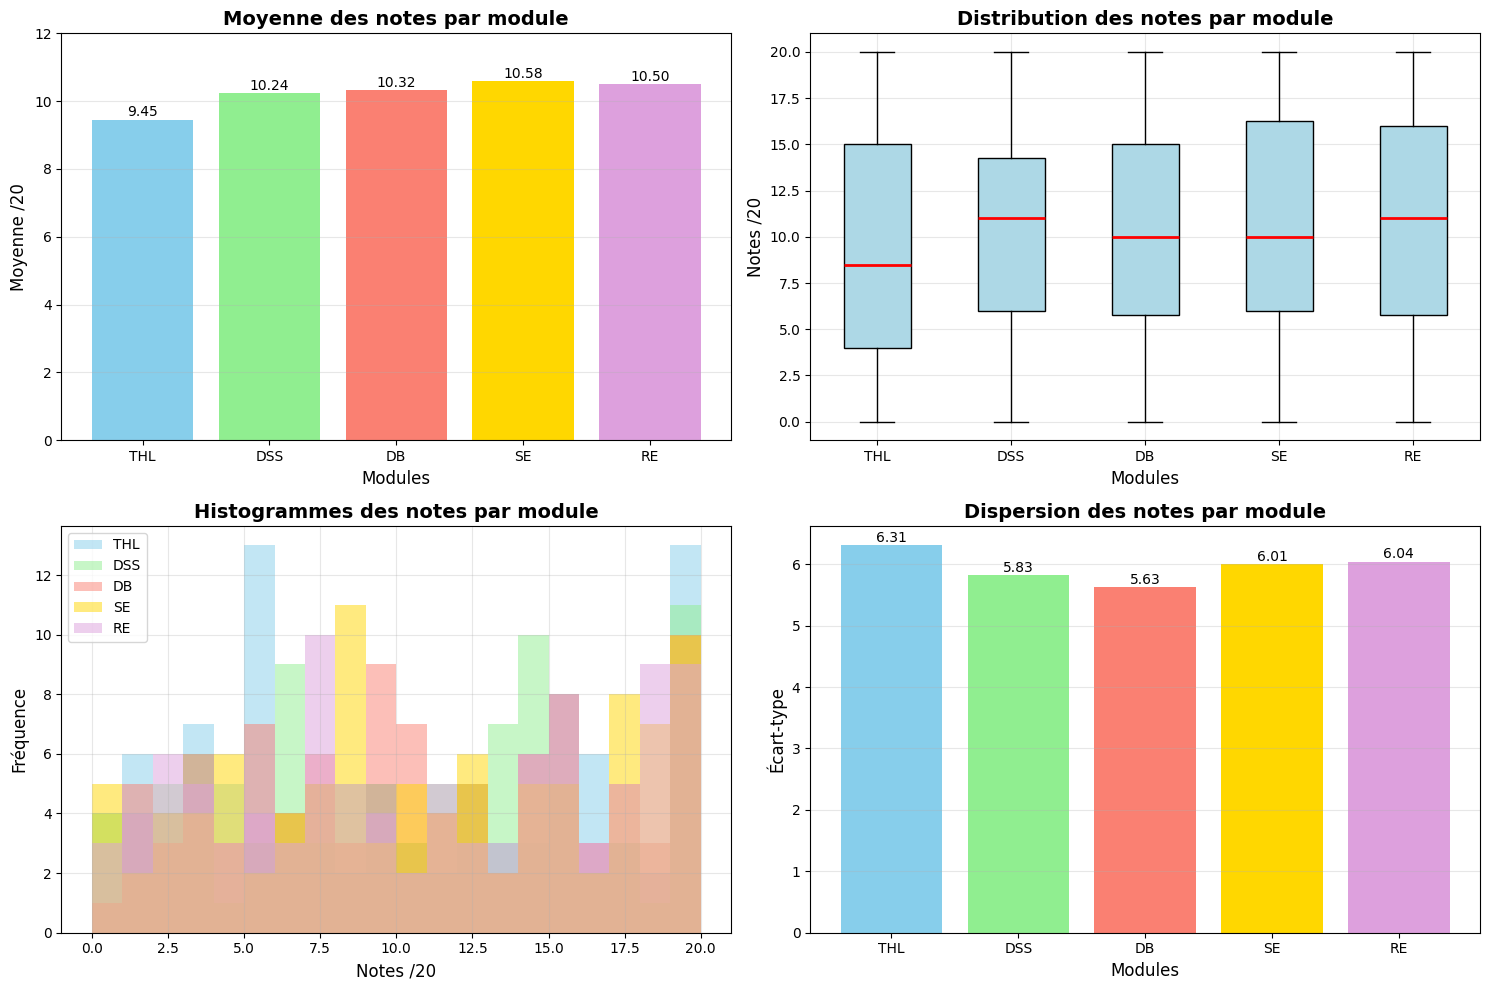

✓ Graphiques affichés


In [4]:
print("\n" + "="*50)
print("ÉTAPE 4 : VISUALISATION")
print("="*50)
print("Création des graphiques...")

# Configuration de la figure
plt.figure(figsize=(15, 10))

# Graphique 1 : Moyenne par module (barres)
print("\n1. DIAGRAMME EN BARRES - MOYENNES")
plt.subplot(2, 2, 1)
bars = plt.bar(modules, mean_per_module, color=['skyblue', 'lightgreen', 'salmon', 'gold', 'plum'])
plt.title('Moyenne des notes par module', fontsize=14, fontweight='bold')
plt.xlabel('Modules', fontsize=12)
plt.ylabel('Moyenne /20', fontsize=12)
plt.ylim(0, 12)
plt.grid(True, alpha=0.3, axis='y')

# Ajout des valeurs sur les barres
for bar, value in zip(bars, mean_per_module):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.1, 
             f'{value:.2f}', ha='center', fontsize=10)

# Graphique 2 : Boxplot par module
print("2. BOÎTES À MOUSTACHES - DISTRIBUTION")
plt.subplot(2, 2, 2)
box_data = [grades_of_students[:, i] for i in range(5)]
plt.boxplot(box_data, labels=modules, patch_artist=True,
            boxprops=dict(facecolor='lightblue'),
            medianprops=dict(color='red', linewidth=2))
plt.title('Distribution des notes par module', fontsize=14, fontweight='bold')
plt.xlabel('Modules', fontsize=12)
plt.ylabel('Notes /20', fontsize=12)
plt.grid(True, alpha=0.3)

# Graphique 3 : Histogrammes superposés
print("3. HISTOGRAMMES SUPERPOSÉS")
plt.subplot(2, 2, 3)
colors = ['skyblue', 'lightgreen', 'salmon', 'gold', 'plum']
for i in range(5):
    plt.hist(grades_of_students[:, i], alpha=0.5, 
             label=modules[i], bins=20, color=colors[i])
plt.title('Histogrammes des notes par module', fontsize=14, fontweight='bold')
plt.xlabel('Notes /20', fontsize=12)
plt.ylabel('Fréquence', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)

# Graphique 4 : Écart-type par module
print("4. DIAGRAMME EN BARRES - ÉCART-TYPE")
plt.subplot(2, 2, 4)
bars_std = plt.bar(modules, std_per_module, color=colors)
plt.title('Dispersion des notes par module', fontsize=14, fontweight='bold')
plt.xlabel('Modules', fontsize=12)
plt.ylabel('Écart-type', fontsize=12)
plt.grid(True, alpha=0.3, axis='y')

for bar, value in zip(bars_std, std_per_module):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.05, 
             f'{value:.2f}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()
print("✓ Graphiques affichés")

In [5]:
print("\n" + "="*50)
print("ÉTAPE 5 : PRATIQUE SUPPLÉMENTAIRE")
print("="*50)

# ÉTAPE 5.1 : Étudiants avec toutes notes > 15
print("\n1. ÉTUDIANTS AVEC TOUTES NOTES > 15 :")
all_above_15 = np.all(grades_of_students > 15, axis=1)
print(f"   np.all(grades_of_students > 15, axis=1)")
print(f"   axis=1 → vérifie sur TOUTES les colonnes (modules)")
students_all_above_15 = np.where(all_above_15)[0]
print(f"   Nombre d'étudiants : {len(students_all_above_15)}")
if len(students_all_above_15) > 0:
    print(f"   Indices : {students_all_above_15}")
else:
    print("   Aucun étudiant n'a toutes ses notes > 15")

# ÉTAPE 5.2 : Top 5 étudiants
print("\n2. TOP 5 ÉTUDIANTS (MEILLEURES MOYENNES) :")
print(f"   Étapes :")
print(f"   1. Trier les indices par moyenne croissante : np.argsort(mean_per_student)")
print(f"   2. Prendre les 5 derniers (meilleurs) : [-5:]")
print(f"   3. Inverser l'ordre : [::-1] (du meilleur au moins bon)")

top_5_indices = np.argsort(mean_per_student)[-5:][::-1]
top_5_means = mean_per_student[top_5_indices]

print(f"\n   Résultats :")
for rank, (idx, mean_val) in enumerate(zip(top_5_indices, top_5_means), 1):
    print(f"   {rank}. Étudiant {idx:3d} : Moyenne = {mean_val:.2f}")

# ÉTAPE 5.3 : Module avec meilleure moyenne
print("\n3. MODULE AVEC LA MEILLEURE MOYENNE :")
best_module_idx = np.argmax(mean_per_module)
best_module = modules[best_module_idx]
best_module_mean = mean_per_module[best_module_idx]
print(f"   np.argmax(mean_per_module) → index du maximum")
print(f"   Index trouvé : {best_module_idx} → module '{best_module}'")
print(f"   Moyenne : {best_module_mean:.2f}")
print(f"   Module performant : {best_module}")

# Classement complet des modules
print(f"\n   Classement complet (du meilleur au moins bon) :")
sorted_indices = np.argsort(mean_per_module)[::-1]
for rank, idx in enumerate(sorted_indices, 1):
    module = modules[idx]
    mean_val = mean_per_module[idx]
    print(f"   {rank}. {module}: {mean_val:.2f}")


ÉTAPE 5 : PRATIQUE SUPPLÉMENTAIRE

1. ÉTUDIANTS AVEC TOUTES NOTES > 15 :
   np.all(grades_of_students > 15, axis=1)
   axis=1 → vérifie sur TOUTES les colonnes (modules)
   Nombre d'étudiants : 0
   Aucun étudiant n'a toutes ses notes > 15

2. TOP 5 ÉTUDIANTS (MEILLEURES MOYENNES) :
   Étapes :
   1. Trier les indices par moyenne croissante : np.argsort(mean_per_student)
   2. Prendre les 5 derniers (meilleurs) : [-5:]
   3. Inverser l'ordre : [::-1] (du meilleur au moins bon)

   Résultats :
   1. Étudiant  24 : Moyenne = 17.00
   2. Étudiant  29 : Moyenne = 16.80
   3. Étudiant  99 : Moyenne = 15.60
   4. Étudiant   3 : Moyenne = 15.60
   5. Étudiant  39 : Moyenne = 15.40

3. MODULE AVEC LA MEILLEURE MOYENNE :
   np.argmax(mean_per_module) → index du maximum
   Index trouvé : 3 → module 'SE'
   Moyenne : 10.58
   Module performant : SE

   Classement complet (du meilleur au moins bon) :
   1. SE: 10.58
   2. RE: 10.50
   3. DB: 10.32
   4. DSS: 10.24
   5. THL: 9.45


In [6]:
print("\n" + "="*60)
print("RÉCAPITULATIF DES RÉSULTATS")
print("="*60)

print("\nA. PERFORMANCES MOYENNES :")
for module, mean_val in zip(modules, mean_per_module):
    print(f"   {module}: {mean_val:.2f}/20")

print("\nB. DISPERSION (écart-type) :")
for module, std_val in zip(modules, std_per_module):
    print(f"   {module}: ±{std_val:.2f}")

print(f"\nC. NOTES 10-15 : {count_10_15}/{grades_of_students.size} "
      f"({count_10_15/grades_of_students.size*100:.1f}%)")

print(f"\nD. MEILLEUR MODULE : {best_module} ({best_module_mean:.2f})")

print(f"\nE. TOP ÉTUDIANT : #{top_5_indices[0]} avec {top_5_means[0]:.2f} de moyenne")

print("\n✓ Analyse terminée avec succès !")


RÉCAPITULATIF DES RÉSULTATS

A. PERFORMANCES MOYENNES :
   THL: 9.45/20
   DSS: 10.24/20
   DB: 10.32/20
   SE: 10.58/20
   RE: 10.50/20

B. DISPERSION (écart-type) :
   THL: ±6.31
   DSS: ±5.83
   DB: ±5.63
   SE: ±6.01
   RE: ±6.04

C. NOTES 10-15 : 145/500 (29.0%)

D. MEILLEUR MODULE : SE (10.58)

E. TOP ÉTUDIANT : #24 avec 17.00 de moyenne

✓ Analyse terminée avec succès !
